<a href="https://colab.research.google.com/github/LennardBehmann/Intro-ML/blob/main/Homework_5/ML_HW5_P1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW5 Problem 1 - Pytorch

1.1 Pytorch bib include

In [25]:
import torch
import matplotlib.pyplot as plt

1.2 use tensors form PP slides

In [26]:
t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]
t_c = torch.tensor(t_c)
t_u = torch.tensor(t_u)

1.3 Change model to no linear and define loss function

In [27]:
def model(t_u, w2 , w1 , b):
  return w2*t_u**2+w1*t_u+b

def loss_fn(t_p, t_c):
  squared_diffs = (t_p- t_c)**2
  return squared_diffs.mean()

1.4 Standardise

In [28]:
t_un = (t_u - t_u.mean()) / t_u.std()
print(t_un)
print(t_un.mean())
print(t_un.std())

tensor([-0.9565,  0.2436,  0.3802,  1.7883,  0.2673, -0.1723, -1.0635, -1.7823,
        -0.2020,  0.5109,  0.9862])
tensor(-1.4088e-07)
tensor(1.)


1.5

In [29]:
w2 = torch.ones((), requires_grad=True)
w1 = torch.ones((), requires_grad=True)
b = torch.zeros((), requires_grad=True)
t_p= model(t_un,w2,w1,b)
print(t_p)

loss=loss_fn(t_p,t_c)
print(loss)


tensor([-0.0416,  0.3029,  0.5248,  4.9862,  0.3388, -0.1426,  0.0675,  1.3944,
        -0.1612,  0.7720,  1.9589], grad_fn=<AddBackward0>)
tensor(154.0711, grad_fn=<MeanBackward0>)


In [30]:
loss.backward()
print("Gradient w2:", w2.grad)
print("Gradient w1:", w1.grad)
print("Gradient b:", b.grad)

Gradient w2: tensor(-15.6626)
Gradient w1: tensor(-14.7641)
Gradient b: tensor(-19.1818)


1.6 Training loop

In [31]:
w2 = torch.ones((), requires_grad=True)
w1 = torch.ones((), requires_grad=True)
b = torch.zeros((), requires_grad=True)

optimizer = torch.optim.SGD([w2, w1, b], lr=0.01)

for epoch in range(1, 5001):

    optimizer.zero_grad()

    t_p= model(t_un,w2,w1,b)

    loss=loss_fn(t_p,t_c)

    loss.backward()

    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item():.6f}")

Epoch 500: Loss = 2.092286
Epoch 1000: Loss = 2.090720
Epoch 1500: Loss = 2.090719
Epoch 2000: Loss = 2.090719
Epoch 2500: Loss = 2.090719
Epoch 3000: Loss = 2.090719
Epoch 3500: Loss = 2.090719
Epoch 4000: Loss = 2.090719
Epoch 4500: Loss = 2.090719
Epoch 5000: Loss = 2.090719


Problem 1b

In [32]:
learningrates = [0.1, 0.01, 0.001, 0.0001]
loss_history = {}
trained_params = {}

for lr in learningrates:

    print(f"\nTraining mit Learning Rate: {lr}")

    w2 = torch.ones((), requires_grad=True)
    w1 = torch.ones((), requires_grad=True)
    b = torch.zeros((), requires_grad=True)

    optimizer = torch.optim.SGD([w2, w1, b], lr=lr)
    loss_values = []

    for epoch in range(1, 5001):

      optimizer.zero_grad()

      t_p= model(t_un,w2,w1,b)

      loss=loss_fn(t_p,t_c)

      loss.backward()

      optimizer.step()
      loss_values.append(loss.item())

      if epoch % 500 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item():.6f}")

    loss_history[lr] = loss_values
    trained_params[lr] = (w2.item(), w1.item(), b.item())


Training mit Learning Rate: 0.1
Epoch 500: Loss = 2.090720
Epoch 1000: Loss = 2.090720
Epoch 1500: Loss = 2.090720
Epoch 2000: Loss = 2.090720
Epoch 2500: Loss = 2.090720
Epoch 3000: Loss = 2.090720
Epoch 3500: Loss = 2.090720
Epoch 4000: Loss = 2.090720
Epoch 4500: Loss = 2.090720
Epoch 5000: Loss = 2.090720

Training mit Learning Rate: 0.01
Epoch 500: Loss = 2.092286
Epoch 1000: Loss = 2.090720
Epoch 1500: Loss = 2.090719
Epoch 2000: Loss = 2.090719
Epoch 2500: Loss = 2.090719
Epoch 3000: Loss = 2.090719
Epoch 3500: Loss = 2.090719
Epoch 4000: Loss = 2.090719
Epoch 4500: Loss = 2.090719
Epoch 5000: Loss = 2.090719

Training mit Learning Rate: 0.001
Epoch 500: Loss = 25.740374
Epoch 1000: Loss = 8.287434
Epoch 1500: Loss = 3.992266
Epoch 2000: Loss = 2.734116
Epoch 2500: Loss = 2.320184
Epoch 3000: Loss = 2.174658
Epoch 3500: Loss = 2.121781
Epoch 4000: Loss = 2.102272
Epoch 4500: Loss = 2.095026
Epoch 5000: Loss = 2.092327

Training mit Learning Rate: 0.0001
Epoch 500: Loss = 119.45

In [33]:
print(loss_history.keys())
print(len(loss_history[0.01]))
print(loss_history[0.01][-1])

dict_keys([0.1, 0.01, 0.001, 0.0001])
5000
2.09071946144104


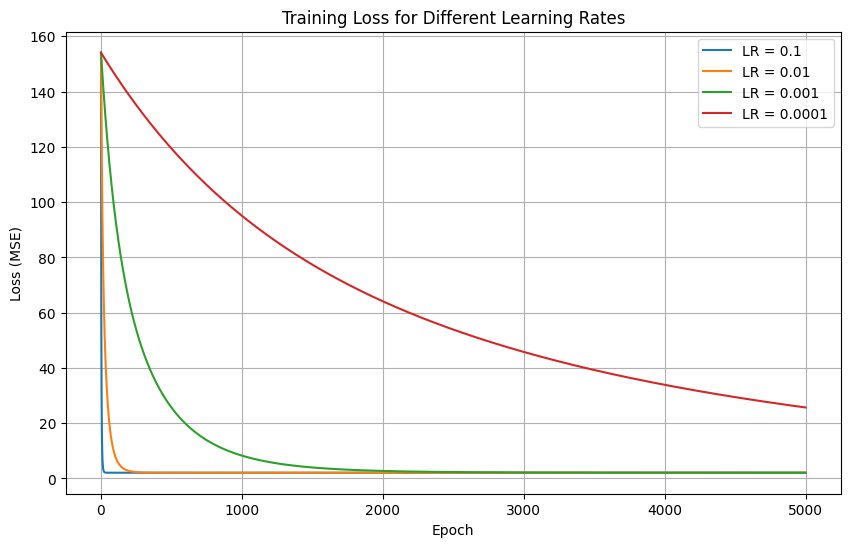

In [34]:
plt.figure(figsize=(10, 6))

for lr in learningrates:
    plt.plot(
        range(1, 5001),
        loss_history[lr],
        label=f"LR = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("Training Loss for Different Learning Rates")
plt.legend()
plt.grid(True)
plt.show()

In [38]:
best_lr = min(learningrates, key=lambda lr: loss_history[lr][-1])

print("Best Learning Rate:", best_lr)
print("Best Final Loss:", loss_history[best_lr][-1])
print("Best Parameters:", trained_params[best_lr])
best_params = trained_params[best_lr]

Best Learning Rate: 0.01
Best Final Loss: 2.09071946144104
Best Parameters: (0.8019199967384338, 9.103358268737793, 9.77095890045166)


Problem 1 c

In [39]:
# Define linear model from Lecture 8
def linear_model(t_u, w, b):
    return w * t_u + b


# Initialize parameters
w_lin = torch.ones((), requires_grad=True)
b_lin = torch.zeros((), requires_grad=True)

# Define optimizer
optimizer_lin = torch.optim.SGD([w_lin, b_lin], lr=0.01)


# Training loop
for epoch in range(1, 5001):

    optimizer_lin.zero_grad()

    t_p_lin = linear_model(t_un, w_lin, b_lin)

    loss_lin = loss_fn(t_p_lin, t_c)

    loss_lin.backward()

    optimizer_lin.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch}: Linear Loss = {loss_lin.item():.6f}")

Epoch 500: Linear Loss = 2.927646
Epoch 1000: Linear Loss = 2.927645
Epoch 1500: Linear Loss = 2.927645
Epoch 2000: Linear Loss = 2.927645
Epoch 2500: Linear Loss = 2.927645
Epoch 3000: Linear Loss = 2.927645
Epoch 3500: Linear Loss = 2.927645
Epoch 4000: Linear Loss = 2.927645
Epoch 4500: Linear Loss = 2.927645
Epoch 5000: Linear Loss = 2.927645


Linear Model Loss: 2.927645206451416
Nonlinear Model Loss: 2.09071946144104
Loss Improvement: 28.59%


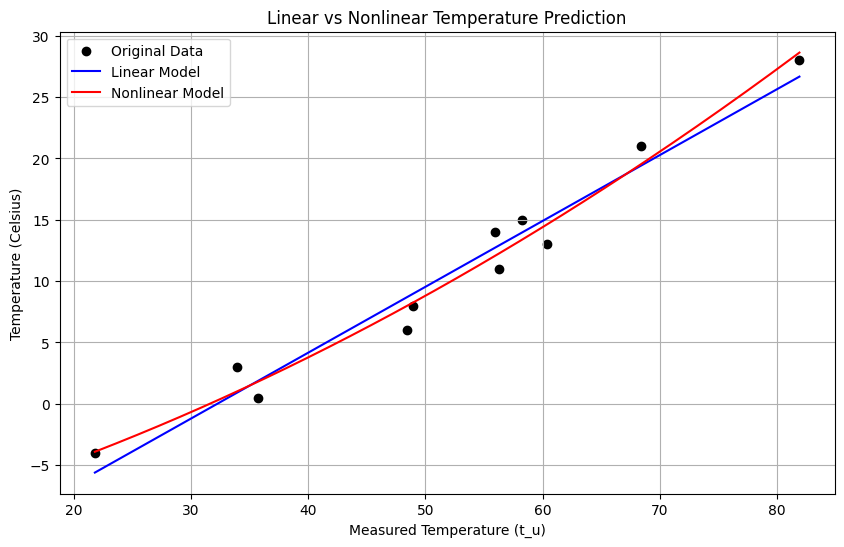

In [40]:
# Compare Linear and Nonlinear Models

with torch.no_grad():

    # Final predictions on the dataset
    linear_predictions = linear_model(t_un, w_lin, b_lin)
    nonlinear_predictions = model(t_un, *best_params)

    # Calculate final losses
    linear_loss = loss_fn(linear_predictions, t_c).item()
    nonlinear_loss = loss_fn(nonlinear_predictions, t_c).item()

print("Linear Model Loss:", linear_loss)
print("Nonlinear Model Loss:", nonlinear_loss)

improvement = (linear_loss - nonlinear_loss) / linear_loss * 100
print(f"Loss Improvement: {improvement:.2f}%")


# Create smooth curves for visualization
t_plot = torch.linspace(t_u.min().item(), t_u.max().item(), 200)

# Apply the same standardization used during training
t_plot_n = (t_plot - t_u.mean()) / t_u.std()

with torch.no_grad():
    linear_curve = linear_model(t_plot_n, w_lin, b_lin)
    nonlinear_curve = model(t_plot_n, *best_params)


# Plot original data and both models
plt.figure(figsize=(10, 6))

plt.scatter(t_u, t_c, label="Original Data", color="black")

plt.plot(t_plot, linear_curve,
         label="Linear Model", color="blue")

plt.plot(t_plot, nonlinear_curve,
         label="Nonlinear Model", color="red")

plt.xlabel("Measured Temperature (t_u)")
plt.ylabel("Temperature (Celsius)")
plt.title("Linear vs Nonlinear Temperature Prediction")

plt.legend()
plt.grid(True)
plt.show()